# Lesion Segmentation — Mobile-UNet Only (Tuned, 50 epochs)

Mobile-UNet only. No external backbones, no pretrained weights, no transfer learning.

## Fixes applied in this revision

| Bug | Fix |
|---|---|
| `ValueError: The name "bneck_drop" is used 2 times` | Every layer name is generated from a unique prefix; a name registry asserts uniqueness before the model is built |
| Custom LR schedule / loss could break `model.save()` | `WarmupCosine`, `combined_loss` and `CBAM` are all `@register_keras_serializable` |
| ASPP at 48 base filters exploded to ~8M params | ASPP branch width is capped (`ASPP_MAX_FILTERS`) |
| Two T4s visible → ambiguous device placement | Pinned to a single GPU |
| `Premature end of JPEG file` spam | Truncated-JPEG guard + decode retry |
| No model-size reporting | Params, FP32 MB and on-disk MB in every summary and the comparison CSV |

## Variants

| VARIANT | Filters | Size | Extras |
|---|---|---|---|
| `mu_a_ablation` | 16 | 256 | v1 topology; only optimizer + loss changed |
| `mu_b_tuned` | 32 | 288 | residual + gates + CBAM |
| `mu_c_wide_aspp` | 48 | 288 | residual + gates + CBAM + capped ASPP |
| `mu_d_deepsup` | 32 | 288 | above + deep supervision |

Run `mu_a_ablation` first to isolate whether v1 failed from the optimizer or the architecture.


In [1]:
# ============================================================
# 1. ENVIRONMENT / GPU
# ============================================================
import os
import sys
import json
import time
import math
import random
import warnings
from pathlib import Path
from collections import Counter

os.environ.setdefault("OPENCV_IO_ENABLE_JASPER", "1")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models

warnings.filterwarnings("ignore", category=UserWarning)
try:
    cv2.setLogLevel(0)          # silence "Premature end of JPEG file" (OpenCV 4.x)
except AttributeError:
    try:
        cv2.utils.logging.setLogLevel(cv2.utils.logging.LOG_LEVEL_SILENT)
    except Exception:
        pass  # older/newer OpenCV builds without a Python logging hook -- warnings are harmless

print("Python     :", sys.version.split()[0])
print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs found :", len(gpus))

if not gpus:
    raise RuntimeError("STOP: No GPU visible. Do not start the 50-epoch run on CPU.")

# Pin to a single GPU -- Kaggle exposes 2x T4 and Keras would otherwise
# place ops ambiguously without a distribution strategy.
try:
    tf.config.set_visible_devices(gpus[0], "GPU")
except Exception as e:
    print("Device-pin note:", e)

for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except Exception as e:
        print("Memory-growth note:", e)

print("Using GPU  :", tf.config.get_visible_devices("GPU"))

# Mixed precision (float16 compute / float32 variables) roughly halves
# activation memory -- this is what fixes ResourceExhaustedError on a T4
# without shrinking the architecture. Output layers already force
# dtype="float32" in the model builder, so sigmoid + loss stay numerically
# stable.
from tensorflow.keras import mixed_precision
mixed_precision.set_global_policy("mixed_float16")
print("Mixed precision policy:", mixed_precision.global_policy())

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

print("Environment: OK")

Python     : 3.12.13
TensorFlow : 2.20.0
Keras      : 3.13.2
GPUs found : 2
Using GPU  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision policy: <DTypePolicy "mixed_float16">
Environment: OK


In [2]:
# ============================================================
# 2. CONFIGURATION
# ============================================================

VARIANT = "mu_b_tuned"
# "mu_a_ablation" | "mu_b_tuned" | "mu_c_wide_aspp" | "mu_d_deepsup"

VARIANTS = {
    "mu_a_ablation": {
        "base_filters": 16, "depth": 4, "img_size": 256, "batch_size": 16,
        "residual": False, "gates": False, "cbam": True, "aspp": False,
        "deep_sup": False, "dropout": 0.0, "activation": "relu",
        "lr": 3e-4, "note": "v1 topology, tuned optimizer/loss only",
    },
    "mu_b_tuned": {
        "base_filters": 32, "depth": 4, "img_size": 256, "batch_size": 6,
        "residual": True, "gates": True, "cbam": True, "aspp": False,
        "deep_sup": False, "dropout": 0.10, "activation": "swish",
        "lr": 3e-4, "note": "main tuned Mobile-UNet (OOM-safe: bs=6, 256px)",
    },
    "mu_c_wide_aspp": {
        "base_filters": 48, "depth": 4, "img_size": 256, "batch_size": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": False, "dropout": 0.12, "activation": "swish",
        "lr": 2.5e-4, "note": "wide + dilated context (OOM-safe: bs=4, 256px)",
    },
    "mu_d_deepsup": {
        "base_filters": 32, "depth": 4, "img_size": 256, "batch_size": 4,
        "residual": True, "gates": True, "cbam": True, "aspp": True,
        "deep_sup": True, "dropout": 0.10, "activation": "swish",
        "lr": 3e-4, "note": "deep supervision (OOM-safe: bs=4, 256px)",
    },
}

# Set True only when you want to build (not train) all four variants as a
# quick duplicate-name / shape self-test. Off by default: building four
# graphs back-to-back on a T4 is unnecessary memory churn once you already
# know one variant fits and trains, per the "model by model" plan.
RUN_VARIANT_SELF_TEST = False

assert VARIANT in VARIANTS, f"Unknown VARIANT: {VARIANT}"
CFG = VARIANTS[VARIANT]

BASE_FILTERS = CFG["base_filters"]
DEPTH        = CFG["depth"]
IMG_SIZE     = CFG["img_size"]
BATCH_SIZE   = CFG["batch_size"]
USE_RESIDUAL = CFG["residual"]
USE_GATES    = CFG["gates"]
USE_CBAM     = CFG["cbam"]
USE_ASPP     = CFG["aspp"]
USE_DEEP_SUP = CFG["deep_sup"]
DROPOUT      = CFG["dropout"]
ACTIVATION   = CFG["activation"]
BASE_LR      = CFG["lr"]

# IMG_SIZE must divide cleanly by 2**DEPTH
assert IMG_SIZE % (2 ** DEPTH) == 0, (
    f"IMG_SIZE {IMG_SIZE} not divisible by 2**{DEPTH}"
)

# ---- Paths -------------------------------------------------
DATASET_DIR = Path("/kaggle/input/datasets/annapoornaak/oral-cancer-dataset-mtech-project")
ANNOTATION_FILE = Path("/kaggle/input/datasets/annapoornaak/metadata-zenodo/Annotation.json")
OUTPUT_ROOT = Path("/kaggle/working/Segmentation Output")

RUN_DIR     = OUTPUT_ROOT / f"lesion_{VARIANT}"
MASKS_DIR   = OUTPUT_ROOT / "lesion_masks_shared"
COMPARE_CSV = OUTPUT_ROOT / "mobileunet_variant_comparison.csv"

for d in (OUTPUT_ROOT, RUN_DIR, MASKS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---- Training ---------------------------------------------
TOTAL_EPOCHS        = 50
LR_WARMUP_EPOCHS    = 3
EARLY_STOP_PATIENCE = 14
WEIGHT_DECAY        = 1e-5
GLOBAL_CLIPNORM     = 1.0
CBAM_REDUCTION      = 8
ASPP_MAX_FILTERS    = 192      # caps ASPP width so 48-filter variant stays sane

# ---- Loss --------------------------------------------------
TVERSKY_ALPHA  = 0.3
TVERSKY_BETA   = 0.7
TVERSKY_GAMMA  = 0.75
BCE_WEIGHT     = 0.5
TVERSKY_WEIGHT = 0.5
DEEP_SUP_WEIGHTS = {"head_out": 1.0, "aux_out_2": 0.4, "aux_out_4": 0.2}

# ---- Data --------------------------------------------------
INCLUDE_NEGATIVES = False
LETTERBOX_RESIZE  = True
VAL_FRACTION      = 0.20

THRESHOLD_GRID = np.round(np.arange(0.10, 0.91, 0.05), 2)

print("=" * 70)
print("ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY")
print("Pretrained backbone : NONE")
print("=" * 70)
print("Variant         :", VARIANT, "-", CFG["note"])
print("Base filters    :", BASE_FILTERS, "(v1 used 16)")
print("Depth           :", DEPTH)
print("Image size      :", IMG_SIZE)
print("Batch size      :", BATCH_SIZE)
print("Residual blocks :", USE_RESIDUAL)
print("Attention gates :", USE_GATES)
print("CBAM bottleneck :", USE_CBAM)
print("ASPP bottleneck :", USE_ASPP, f"(capped at {ASPP_MAX_FILTERS} filters)")
print("Deep supervision:", USE_DEEP_SUP)
print("Activation      :", ACTIVATION)
print("Optimizer       : AdamW warmup+cosine, base LR", BASE_LR)
print("Epochs          :", TOTAL_EPOCHS)
print("Run dir         :", RUN_DIR)
print("=" * 70)

ARCHITECTURE FAMILY : Mobile-UNet (depthwise separable) ONLY
Pretrained backbone : NONE
Variant         : mu_b_tuned - main tuned Mobile-UNet (OOM-safe: bs=6, 256px)
Base filters    : 32 (v1 used 16)
Depth           : 4
Image size      : 256
Batch size      : 6
Residual blocks : True
Attention gates : True
CBAM bottleneck : True
ASPP bottleneck : False (capped at 192 filters)
Deep supervision: False
Activation      : swish
Optimizer       : AdamW warmup+cosine, base LR 0.0003
Epochs          : 50
Run dir         : /kaggle/working/Segmentation Output/lesion_mu_b_tuned


In [3]:
# ============================================================
# 3. LOAD + CHECK COCO JSON
# ============================================================
assert DATASET_DIR.exists(), f"STOP: dataset dir not found: {DATASET_DIR}"
assert ANNOTATION_FILE.exists(), f"STOP: annotation file not found: {ANNOTATION_FILE}"

with open(ANNOTATION_FILE, "r") as f:
    coco = json.load(f)

assert {"images", "annotations", "categories"}.issubset(coco.keys())

name_to_id = {c["name"]: c["id"] for c in coco["categories"]}
assert "Lesion" in name_to_id, f"No 'Lesion' category. Found: {list(name_to_id)}"

CAT_LESION = name_to_id["Lesion"]
CAT_ORAL = name_to_id.get("Oral Cavity")

cat_counts = Counter(a["category_id"] for a in coco["annotations"])

EXPECTED = {"images": 3000, "annotations": 6358, "lesion": 3358, "oral": 3000}
observed = {
    "images": len(coco["images"]),
    "annotations": len(coco["annotations"]),
    "lesion": cat_counts[CAT_LESION],
    "oral": cat_counts.get(CAT_ORAL, 0),
}

print(f"{'key':<14}{'v1 expected':>14}{'observed':>12}{'match':>8}")
for k in EXPECTED:
    print(f"{k:<14}{EXPECTED[k]:>14}{observed[k]:>12}"
          f"{('yes' if EXPECTED[k] == observed[k] else 'NO'):>8}")

key              v1 expected    observed   match
images                  3000        3000     yes
annotations             6358        6358     yes
lesion                  3358        3358     yes
oral                    3000        3000     yes


In [4]:
# ============================================================
# 4. IMAGE ID -> FILE PATH  +  LESION GROUPING
# ============================================================
IMAGE_EXTS = (".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff")

filename_to_path = {}
for p in DATASET_DIR.rglob("*"):
    if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
        filename_to_path.setdefault(p.name, p)

images_info = {img["id"]: img for img in coco["images"]}

image_id_to_path, unmatched = {}, []
for image_id, info in images_info.items():
    fname = Path(info["file_name"]).name
    if fname in filename_to_path:
        image_id_to_path[image_id] = filename_to_path[fname]
    else:
        unmatched.append((image_id, fname))

print("JSON images :", len(images_info))
print("Matched     :", len(image_id_to_path))
print("Unmatched   :", len(unmatched), unmatched[:3])

assert len(image_id_to_path) > 0, "STOP: no images matched."

lesion_by_image = {}
for ann in coco["annotations"]:
    if ann["category_id"] == CAT_LESION:
        lesion_by_image.setdefault(ann["image_id"], []).append(ann)

negative_ids = sorted(set(images_info) - set(lesion_by_image))

print("Images WITH lesion    :", len(lesion_by_image))
print("Images WITHOUT lesion :", len(negative_ids))

JSON images : 3000
Matched     : 3000
Unmatched   : 0 []
Images WITH lesion    : 2271
Images WITHOUT lesion : 729


In [5]:
# ============================================================
# 5. ROBUST IMAGE READER + MASK GENERATION
# ============================================================
def safe_imread(path, flags=cv2.IMREAD_COLOR):
    """Decode an image, tolerating truncated JPEG tails.

    Some files in this dataset end mid-stream ('Premature end of JPEG file').
    cv2.imread still returns the decoded portion; this wrapper just makes the
    failure mode explicit instead of silently returning None.
    """
    img = cv2.imread(str(path), flags)
    if img is not None:
        return img
    try:
        buf = np.fromfile(str(path), dtype=np.uint8)
        img = cv2.imdecode(buf, flags)
    except Exception:
        img = None
    return img


def create_lesion_mask(image_id):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        return None

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        return None

    h, w = image.shape[:2]
    mask = np.zeros((h, w), dtype=np.uint8)

    for ann in lesion_by_image.get(image_id, []):
        seg = ann.get("segmentation", [])
        if not seg:
            continue
        polygons = [seg] if isinstance(seg[0], (int, float)) else seg
        for poly in polygons:
            if len(poly) < 6:
                continue
            pts = np.asarray(poly, dtype=np.float32).reshape(-1, 2)
            pts = np.round(pts).astype(np.int32)
            pts[:, 0] = np.clip(pts[:, 0], 0, w - 1)
            pts[:, 1] = np.clip(pts[:, 1], 0, h - 1)
            cv2.fillPoly(mask, [pts], 255)

    return mask


_m = create_lesion_mask(next(iter(lesion_by_image)))
assert _m is not None and _m.dtype == np.uint8
assert set(np.unique(_m)).issubset({0, 255}) and np.count_nonzero(_m) > 0
print("Mask unit test: PASS  shape =", _m.shape,
      " positive px =", int(np.count_nonzero(_m)))
del _m

Mask unit test: PASS  shape = (3456, 4608)  positive px = 141110


In [6]:
# ============================================================
# 5b. SEQUENTIAL MASK WRITE + DATASET INDEX (RAM-safe, cached)
# ============================================================
records, failures = [], []

target_ids = sorted(lesion_by_image)
if INCLUDE_NEGATIVES:
    target_ids = sorted(set(target_ids) | set(negative_ids))

for image_id in tqdm(target_ids, desc="Masks"):
    image_path = image_id_to_path.get(image_id)
    if image_path is None:
        failures.append((image_id, "missing_image"))
        continue

    mask_path = MASKS_DIR / f"{image_id}.png"

    if mask_path.exists():
        cached = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
        if cached is None:
            mask_path.unlink(missing_ok=True)
            failures.append((image_id, "cache_unreadable"))
            continue
        pos, shape_hw = int(np.count_nonzero(cached)), cached.shape
        del cached
    else:
        mask = create_lesion_mask(image_id)
        if mask is None:
            failures.append((image_id, "mask_failed"))
            continue

        pos, shape_hw = int(np.count_nonzero(mask)), mask.shape
        if pos == 0 and not INCLUDE_NEGATIVES:
            failures.append((image_id, "empty_mask"))
            del mask
            continue

        if not cv2.imwrite(str(mask_path), mask):
            failures.append((image_id, "write_failed"))
            del mask
            continue
        del mask

    records.append({
        "image_id": image_id,
        "image_path": str(image_path),
        "mask_path": str(mask_path),
        "lesion_px": pos,
        "lesion_frac": pos / float(shape_hw[0] * shape_hw[1]),
    })

dataset_df = pd.DataFrame(records)
assert len(dataset_df) > 0, "STOP: no usable image/mask pairs."
dataset_df.to_csv(RUN_DIR / "lesion_dataset_index.csv", index=False)

print("Usable pairs :", len(dataset_df), " (v1 had 2271)")
print("Failures     :", len(failures), Counter(r for _, r in failures))

Masks:   0%|          | 0/2271 [00:00<?, ?it/s]

Premature end of JPEG file


Usable pairs : 2271  (v1 had 2271)
Failures     : 0 Counter()


Mean lesion pixel fraction : 0.1173  (11.73%)
Median                     : 0.0670
Background : foreground    : 7.5 : 1
Images with <1% lesion     : 254
Images with <5% lesion     : 974


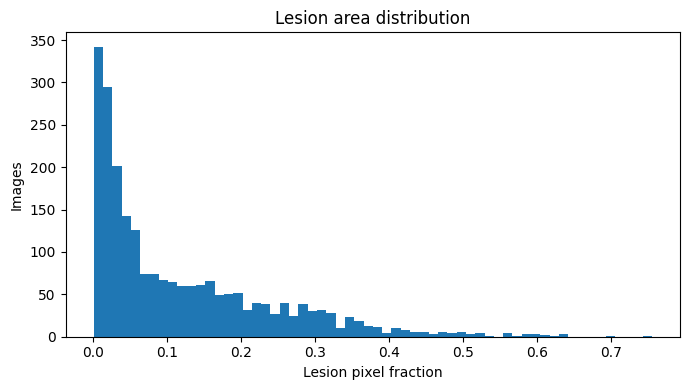

In [7]:
# ============================================================
# 5c. CLASS-IMBALANCE DIAGNOSTIC
# ============================================================
frac = dataset_df["lesion_frac"].values
pos_rate = float(frac.mean())

print(f"Mean lesion pixel fraction : {pos_rate:.4f}  ({pos_rate*100:.2f}%)")
print(f"Median                     : {np.median(frac):.4f}")
print(f"Background : foreground    : {(1-pos_rate)/max(pos_rate,1e-9):.1f} : 1")
print(f"Images with <1% lesion     : {int((frac < 0.01).sum())}")
print(f"Images with <5% lesion     : {int((frac < 0.05).sum())}")

plt.figure(figsize=(7, 4))
plt.hist(frac, bins=60)
plt.xlabel("Lesion pixel fraction"); plt.ylabel("Images")
plt.title("Lesion area distribution")
plt.tight_layout()
plt.savefig(RUN_DIR / "lesion_area_distribution.png", dpi=140)
plt.show()

In [8]:
# ============================================================
# 6. STRATIFIED SPLIT
# ============================================================
bins = pd.qcut(dataset_df["lesion_frac"].rank(method="first"),
               q=5, labels=False, duplicates="drop")

train_df, val_df = train_test_split(
    dataset_df, test_size=VAL_FRACTION, random_state=SEED,
    shuffle=True, stratify=bins,
)
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)

assert set(train_df["image_id"]).isdisjoint(set(val_df["image_id"])), "LEAK!"
assert len(train_df) >= BATCH_SIZE, "Train set smaller than one batch."

print("Total :", len(dataset_df), " Train :", len(train_df), " Val :", len(val_df))
print("Mean lesion frac  train:", round(train_df["lesion_frac"].mean(), 4),
      " val:", round(val_df["lesion_frac"].mean(), 4))
print("Split: PASS (stratified, no overlap)")

Total : 2271  Train : 1816  Val : 455
Mean lesion frac  train: 0.1172  val: 0.1177
Split: PASS (stratified, no overlap)


In [9]:
# ============================================================
# 7. LOADER + tf.data
# ============================================================
def letterbox(img, size, interp, pad_value=0):
    """Aspect-preserving resize into a size x size canvas."""
    h, w = img.shape[:2]
    scale = size / max(h, w)
    nh, nw = max(1, int(round(h * scale))), max(1, int(round(w * scale)))
    resized = cv2.resize(img, (nw, nh), interpolation=interp)

    top, left = (size - nh) // 2, (size - nw) // 2
    if resized.ndim == 3:
        canvas = np.full((size, size, resized.shape[2]), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw, :] = resized
    else:
        canvas = np.full((size, size), pad_value, dtype=resized.dtype)
        canvas[top:top + nh, left:left + nw] = resized
    return canvas


def _load_np(image_path, mask_path):
    image_path = image_path.numpy().decode("utf-8")
    mask_path = mask_path.numpy().decode("utf-8")

    image = safe_imread(image_path, cv2.IMREAD_COLOR)
    if image is None:
        raise ValueError(f"Unreadable image: {image_path}")
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        raise ValueError(f"Unreadable mask: {mask_path}")

    if LETTERBOX_RESIZE:
        image = letterbox(image, IMG_SIZE, cv2.INTER_AREA, 0)
        mask = letterbox(mask, IMG_SIZE, cv2.INTER_NEAREST, 0)
    else:
        image = cv2.resize(image, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_NEAREST)

    return (np.ascontiguousarray(image, dtype=np.float32),
            np.ascontiguousarray((mask > 127).astype(np.float32)[..., None]))


def tf_load(image_path, mask_path):
    image, mask = tf.py_function(_load_np, [image_path, mask_path],
                                 [tf.float32, tf.float32])
    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask

In [10]:
# ============================================================
# 7b. AUGMENTATION (orientation-safe, geometry-consistent)
# ============================================================
def _rand_affine(image, mask):
    """Rotation +/-15 deg, shift +/-8%, zoom 0.9-1.1 -- identical for both."""
    angle = tf.random.uniform([], -15.0, 15.0) * math.pi / 180.0
    zoom = tf.random.uniform([], 0.90, 1.10)
    dx = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE
    dy = tf.random.uniform([], -0.08, 0.08) * IMG_SIZE

    cos_a, sin_a = tf.cos(angle) / zoom, tf.sin(angle) / zoom
    cx = cy = IMG_SIZE / 2.0

    a2 = cx - cx * cos_a + cy * sin_a + dx
    b2 = cy - cx * sin_a - cy * cos_a + dy
    transform = tf.stack([cos_a, -sin_a, a2, sin_a, cos_a, b2, 0.0, 0.0])[None, :]

    stacked = tf.concat([image, mask], axis=-1)[None, ...]
    warped = tf.raw_ops.ImageProjectiveTransformV3(
        images=stacked, transforms=transform,
        output_shape=tf.constant([IMG_SIZE, IMG_SIZE], tf.int32),
        interpolation="BILINEAR", fill_mode="CONSTANT", fill_value=0.0,
    )[0]

    return warped[..., :3], tf.cast(warped[..., 3:] > 0.5, tf.float32)


def augment(image, mask):
    if tf.random.uniform([]) > 0.5:                 # horizontal flip only
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform([]) > 0.3:
        image, mask = _rand_affine(image, mask)

    image = tf.image.random_brightness(image, 20.0)          # on [0,255]
    image = tf.image.random_contrast(image, 0.85, 1.15)
    image = tf.image.random_saturation(image, 0.85, 1.15)
    image = tf.image.random_hue(image, 0.02)
    image = tf.clip_by_value(image, 0.0, 255.0)

    image.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return image, mask


def add_deep_sup_targets(image, mask):
    """Targets keyed by output name so Keras matches them unambiguously."""
    m2 = tf.image.resize(mask, [IMG_SIZE // 2, IMG_SIZE // 2], method="nearest")
    m4 = tf.image.resize(mask, [IMG_SIZE // 4, IMG_SIZE // 4], method="nearest")
    return image, {"head_out": mask, "aux_out_2": m2, "aux_out_4": m4}


def make_dataset(df, training):
    ds = tf.data.Dataset.from_tensor_slices(
        (df["image_path"].values, df["mask_path"].values))

    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)

    ds = ds.map(tf_load, num_parallel_calls=tf.data.AUTOTUNE,
                deterministic=not training)

    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE, deterministic=False)

    if USE_DEEP_SUP:
        ds = ds.map(add_deep_sup_targets, num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.batch(BATCH_SIZE, drop_remainder=training)
    return ds.prefetch(tf.data.AUTOTUNE)


def main_target(y):
    """Extract the full-resolution mask regardless of deep-supervision mode."""
    return y["head_out"] if isinstance(y, dict) else y


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)

_xb, _yb = next(iter(train_ds))
_main = main_target(_yb)

print("Image batch:", _xb.shape, "range",
      float(tf.reduce_min(_xb)), "-", float(tf.reduce_max(_xb)))
print("Mask batch :", _main.shape, "unique", np.unique(_main.numpy()))
assert np.all(np.isfinite(_xb.numpy()))
assert set(np.unique(_main.numpy())).issubset({0.0, 1.0})
print("Pipeline: PASS")

I0000 00:00:1790069136.238858      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


Image batch: (6, 256, 256, 3) range 0.0 - 255.0
Mask batch : (6, 256, 256, 1) unique [0. 1.]
Pipeline: PASS


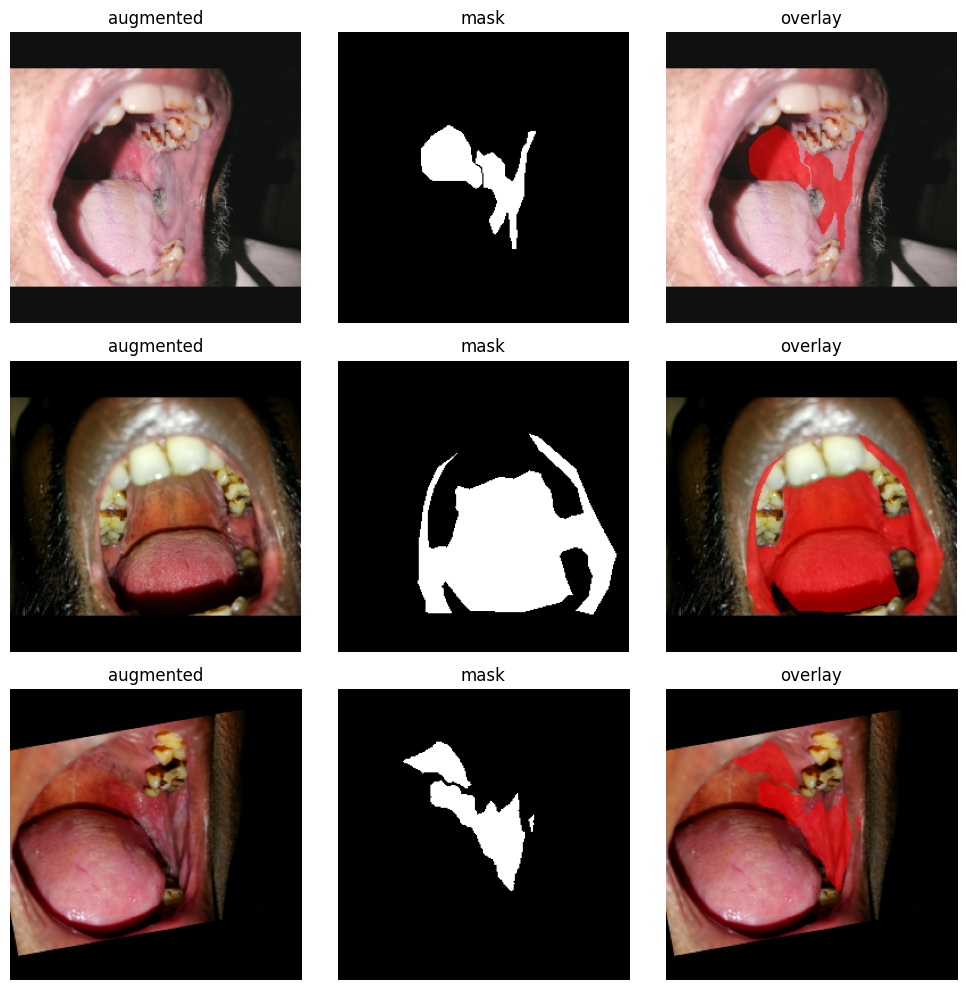

In [11]:
# ============================================================
# 7c. VISUAL CHECK OF AUGMENTED BATCH
# ============================================================
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for i in range(3):
    img = _xb[i].numpy().astype(np.uint8)
    msk = _main[i].numpy()[..., 0]
    ov = img.copy()
    sel = msk > 0.5
    ov[sel] = (0.45 * ov[sel] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)

    axes[i, 0].imshow(img);              axes[i, 0].set_title("augmented")
    axes[i, 1].imshow(msk, cmap="gray"); axes[i, 1].set_title("mask")
    axes[i, 2].imshow(ov);               axes[i, 2].set_title("overlay")
    for c in range(3):
        axes[i, c].axis("off")

plt.tight_layout()
plt.savefig(RUN_DIR / "augmentation_check.png", dpi=140)
plt.show()

In [12]:
# ============================================================
# 8. LOSSES + METRICS (registered so model.save() works)
# ============================================================
SMOOTH = 1e-6


def _flat(y_true, y_pred):
    y_true = tf.cast(y_true, tf.float32)
    y_pred = tf.cast(y_pred, tf.float32)
    n = tf.shape(y_true)[0]
    return tf.reshape(y_true, [n, -1]), tf.reshape(y_pred, [n, -1])


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def dice_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def iou_coef(y_true, y_pred):
    yt, yp = _flat(y_true, y_pred)
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_dice(y_true, y_pred):
    """Hard Dice at 0.5 -- the reported number."""
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    denom = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1)
    return tf.reduce_mean((2.0 * inter + SMOOTH) / (denom + SMOOTH))


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def bin_iou(y_true, y_pred):
    yt, yp = _flat(y_true, tf.cast(y_pred > 0.5, tf.float32))
    inter = tf.reduce_sum(yt * yp, axis=1)
    union = tf.reduce_sum(yt, axis=1) + tf.reduce_sum(yp, axis=1) - inter
    return tf.reduce_mean((inter + SMOOTH) / (union + SMOOTH))


def tversky_index(y_true, y_pred, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA):
    yt, yp = _flat(y_true, y_pred)
    tp = tf.reduce_sum(yt * yp, axis=1)
    fp = tf.reduce_sum((1.0 - yt) * yp, axis=1)
    fn = tf.reduce_sum(yt * (1.0 - yp), axis=1)
    return tf.reduce_mean((tp + SMOOTH) / (tp + alpha * fp + beta * fn + SMOOTH))


def focal_tversky_loss(y_true, y_pred, gamma=TVERSKY_GAMMA):
    return tf.pow(1.0 - tversky_index(y_true, y_pred), gamma)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
def combined_loss(y_true, y_pred):
    y_pred = tf.clip_by_value(y_pred, 1e-7, 1.0 - 1e-7)
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return BCE_WEIGHT * bce + TVERSKY_WEIGHT * focal_tversky_loss(y_true, y_pred)


METRICS = [dice_coef, iou_coef, bin_dice, bin_iou]

# quick numerical sanity check
_t = tf.constant(np.random.randint(0, 2, (2, 8, 8, 1)).astype(np.float32))
_p = tf.constant(np.random.rand(2, 8, 8, 1).astype(np.float32))
for fn in (dice_coef, iou_coef, bin_dice, bin_iou, combined_loss):
    v = float(fn(_t, _p))
    assert np.isfinite(v), f"{fn.__name__} not finite"
assert abs(float(dice_coef(_t, _t)) - 1.0) < 1e-4, "dice_coef(y,y) != 1"
assert float(combined_loss(_t, _t)) < 0.05, "loss on perfect prediction too high"
del _t, _p

print("Losses and metrics defined and sanity-checked.")
print("Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)")

Losses and metrics defined and sanity-checked.
Loss = 0.5*BCE + 0.5*FocalTversky(alpha=0.3, beta=0.7, gamma=0.75)


In [13]:
# ============================================================
# 9. LAYER-NAME REGISTRY
#    Guarantees the duplicate-name crash can never happen again.
# ============================================================
class NameRegistry:
    """Hands out guaranteed-unique layer names and records every one."""

    def __init__(self):
        self.used = set()

    def reset(self):
        self.used = set()

    def __call__(self, name):
        if name in self.used:
            raise ValueError(
                f"Duplicate layer name generated: '{name}'. "
                "This is a builder bug -- fix the name prefix."
            )
        self.used.add(name)
        return name


NAMES = NameRegistry()
print("Name registry ready. Every layer name is asserted unique at build time.")

Name registry ready. Every layer name is asserted unique at build time.


In [14]:
# ============================================================
# 10. MOBILE-UNET BLOCKS (100% depthwise separable)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class CBAM(layers.Layer):
    """Channel + spatial attention. No Lambda -> clean .keras serialization."""

    def __init__(self, reduction_ratio=8, spatial_kernel=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)
        self.spatial_kernel = int(spatial_kernel)

    def build(self, input_shape):
        c = int(input_shape[-1])
        r = max(c // self.reduction_ratio, 4)
        self.mlp1 = layers.Dense(r, activation="relu", name="ch_reduce")
        self.mlp2 = layers.Dense(c, activation=None, name="ch_expand")
        self.sp_conv = layers.Conv2D(1, self.spatial_kernel, padding="same",
                                     activation="sigmoid", name="sp_conv")
        super().build(input_shape)

    def call(self, x):
        avg = tf.reduce_mean(x, axis=[1, 2])
        mx = tf.reduce_max(x, axis=[1, 2])
        att = tf.nn.sigmoid(self.mlp2(self.mlp1(avg)) + self.mlp2(self.mlp1(mx)))
        x = x * att[:, None, None, :]

        sp = tf.concat([tf.reduce_mean(x, -1, keepdims=True),
                        tf.reduce_max(x, -1, keepdims=True)], axis=-1)
        return x * self.sp_conv(sp)

    def get_config(self):
        cfg = super().get_config()
        cfg.update({"reduction_ratio": self.reduction_ratio,
                    "spatial_kernel": self.spatial_kernel})
        return cfg


def sep_block(x, filters, prefix, act, dilation=1):
    """Separable conv -> BN -> activation."""
    x = layers.SeparableConv2D(
        filters, 3, padding="same", use_bias=False, dilation_rate=dilation,
        name=NAMES(f"{prefix}_sep"))(x)
    x = layers.BatchNormalization(name=NAMES(f"{prefix}_bn"))(x)
    return layers.Activation(act, name=NAMES(f"{prefix}_act"))(x)


def residual_sep_block(x, filters, prefix, act, dropout=0.0):
    """Two separable convs + 1x1 projection shortcut.
    Replaces v1's zero-init adapters, which had no pretrained weights to adapt."""
    shortcut = layers.Conv2D(filters, 1, padding="same", use_bias=False,
                             name=NAMES(f"{prefix}_sc"))(x)
    shortcut = layers.BatchNormalization(name=NAMES(f"{prefix}_sc_bn"))(shortcut)

    y = sep_block(x, filters, f"{prefix}_a", act)
    if dropout > 0:
        y = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(y)
    y = layers.SeparableConv2D(filters, 3, padding="same", use_bias=False,
                               name=NAMES(f"{prefix}_b_sep"))(y)
    y = layers.BatchNormalization(name=NAMES(f"{prefix}_b_bn"))(y)

    out = layers.Add(name=NAMES(f"{prefix}_add"))([shortcut, y])
    return layers.Activation(act, name=NAMES(f"{prefix}_out"))(out)


def double_block(x, filters, prefix, residual, act, dropout):
    """Either two plain separable convs (v1 style) or one residual block."""
    if residual:
        return residual_sep_block(x, filters, prefix, act, dropout)
    x = sep_block(x, filters, f"{prefix}_a", act)
    x = sep_block(x, filters, f"{prefix}_b", act)
    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES(f"{prefix}_inner_drop"))(x)
    return x


def attention_gate(skip, gating, filters, prefix):
    """Additive attention gate applied to a skip connection."""
    g = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_g"))(gating)
    s = layers.Conv2D(filters, 1, padding="same", name=NAMES(f"{prefix}_x"))(skip)
    a = layers.Add(name=NAMES(f"{prefix}_add"))([g, s])
    a = layers.Activation("relu", name=NAMES(f"{prefix}_relu"))(a)
    psi = layers.Conv2D(1, 1, padding="same", activation="sigmoid",
                        name=NAMES(f"{prefix}_psi"))(a)
    return layers.Multiply(name=NAMES(f"{prefix}_mul"))([skip, psi])


def sep_aspp(x, filters, prefix, act, rates=(1, 2, 4, 8)):
    """Separable atrous spatial pyramid. Branch width is capped so the
    48-filter variant does not explode to millions of parameters."""
    branch_f = int(min(filters, ASPP_MAX_FILTERS))

    branches = [layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                              name=NAMES(f"{prefix}_b0_conv"))(x)]
    for i, r in enumerate(rates[1:], start=1):
        branches.append(sep_block(x, branch_f, f"{prefix}_b{i}", act, dilation=r))

    pooled = layers.GlobalAveragePooling2D(
        keepdims=True, name=NAMES(f"{prefix}_gap"))(x)
    pooled = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_gap_conv"))(pooled)
    pooled = layers.UpSampling2D(size=(int(x.shape[1]), int(x.shape[2])),
                                 interpolation="bilinear",
                                 name=NAMES(f"{prefix}_gap_up"))(pooled)
    branches.append(pooled)

    merged = layers.Concatenate(name=NAMES(f"{prefix}_cat"))(branches)
    merged = layers.Conv2D(branch_f, 1, padding="same", use_bias=False,
                           name=NAMES(f"{prefix}_proj"))(merged)
    merged = layers.BatchNormalization(name=NAMES(f"{prefix}_proj_bn"))(merged)
    return layers.Activation(act, name=NAMES(f"{prefix}_proj_act"))(merged)


print("Mobile-UNet blocks defined (no external backbone, no pretrained weights).")

Mobile-UNet blocks defined (no external backbone, no pretrained weights).


In [15]:
# ============================================================
# 11. MOBILE-UNET BUILDER
# ============================================================
def build_mobile_unet(img_size, base_filters, depth,
                      residual, gates, cbam, aspp, deep_sup,
                      dropout, act, name="mobile_unet"):
    NAMES.reset()

    inputs = layers.Input(shape=(img_size, img_size, 3), name=NAMES("input_image"))
    x = layers.Rescaling(1.0 / 255.0, name=NAMES("rescale"))(inputs)

    # ---------------- Encoder ----------------
    skips, filters = [], base_filters
    for i in range(depth):
        enc_drop = dropout * 0.5 if i >= depth - 2 else 0.0
        x = double_block(x, filters, f"enc{i}", residual, act, enc_drop)
        skips.append(x)
        x = layers.MaxPooling2D(2, name=NAMES(f"enc{i}_pool"))(x)
        filters *= 2

    # ---------------- Bottleneck ----------------
    # Dropout is applied exactly ONCE here, after CBAM, under a unique name.
    if aspp:
        x = sep_aspp(x, filters, "bneck_aspp", act)
        filters = int(x.shape[-1])          # ASPP may cap the width
    else:
        x = double_block(x, filters, "bneck", residual, act, 0.0)

    if cbam:
        x = CBAM(CBAM_REDUCTION, name=NAMES("bottleneck_cbam"))(x)

    if dropout > 0:
        x = layers.SpatialDropout2D(dropout, name=NAMES("bottleneck_drop"))(x)

    # ---------------- Decoder ----------------
    aux_outputs = {}
    dec_filters = base_filters * (2 ** (depth - 1))

    for i in reversed(range(depth)):
        x = layers.UpSampling2D(2, interpolation="bilinear",
                                name=NAMES(f"dec{i}_up"))(x)

        skip = skips[i]
        if gates:
            skip = attention_gate(skip, x, max(dec_filters // 2, 8), f"dec{i}_gate")

        x = layers.Concatenate(name=NAMES(f"dec{i}_cat"))([x, skip])
        x = double_block(x, dec_filters, f"dec{i}", residual, act,
                         dropout if i >= 2 else 0.0)

        # deep-supervision heads: i=2 -> /4, i=1 -> /2
        if deep_sup and i in (1, 2):
            head_name = f"aux_out_{2 ** i}"
            aux_outputs[head_name] = layers.Conv2D(
                1, 1, activation="sigmoid", dtype="float32",
                name=NAMES(head_name))(x)

        dec_filters = max(dec_filters // 2, base_filters)

    main_out = layers.Conv2D(1, 1, activation="sigmoid", dtype="float32",
                             name=NAMES("head_out"))(x)

    if deep_sup:
        outputs = [main_out, aux_outputs["aux_out_2"], aux_outputs["aux_out_4"]]
        model = models.Model(inputs, outputs, name=name)
    else:
        model = models.Model(inputs, main_out, name=name)

    # final guard -- Keras would raise anyway, but this gives a clear message
    all_names = [l.name for l in model.layers]
    dupes = [n for n, c in Counter(all_names).items() if c > 1]
    assert not dupes, f"Duplicate layer names survived the registry: {dupes}"

    return model


print("Builder defined.")

Builder defined.


### Build-time self-test

All four variants are constructed and immediately discarded. If any variant would
raise a duplicate-name error, it surfaces here — before any training time is spent.

In [16]:
# ============================================================
# 11b. SELF-TEST -- BUILD EVERY VARIANT (optional, see cell 2)
# ============================================================
if not RUN_VARIANT_SELF_TEST:
    print("Skipped (RUN_VARIANT_SELF_TEST = False in cell 2).")
    print("The selected variant is still verified by the hard preflight below.")
else:
    print(f"{'variant':<18}{'params':>12}{'FP32 MB':>10}{'outputs':>10}  status")
    print("-" * 64)

    _size_table = {}

    for _name, _cfg in VARIANTS.items():
        tf.keras.backend.clear_session()
        try:
            _m = build_mobile_unet(
                img_size=_cfg["img_size"], base_filters=_cfg["base_filters"],
                depth=_cfg["depth"], residual=_cfg["residual"], gates=_cfg["gates"],
                cbam=_cfg["cbam"], aspp=_cfg["aspp"], deep_sup=_cfg["deep_sup"],
                dropout=_cfg["dropout"], act=_cfg["activation"], name=f"probe_{_name}",
            )
            _p = int(_m.count_params())
            _mb = _p * 4 / (1024 ** 2)
            _n_out = len(_m.outputs)
            _size_table[_name] = {"params": _p, "fp32_mb": round(_mb, 2)}
            print(f"{_name:<18}{_p:>12,}{_mb:>10.2f}{_n_out:>10}  OK")
            del _m
        except Exception as e:
            print(f"{_name:<18}{'-':>12}{'-':>10}{'-':>10}  FAIL: {e}")
            raise

    print("-" * 64)
    print(f"{'v1_original':<18}{311319:>12,}{311319 * 4 / 1024 ** 2:>10.2f}{1:>10}  reference")
    print()
    print("All variants build cleanly. No duplicate layer names.")

    tf.keras.backend.clear_session()

Skipped (RUN_VARIANT_SELF_TEST = False in cell 2).
The selected variant is still verified by the hard preflight below.


In [17]:
# ============================================================
# 12. BUILD THE SELECTED MODEL
# ============================================================
tf.keras.backend.clear_session()
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

model = build_mobile_unet(
    img_size=IMG_SIZE,
    base_filters=BASE_FILTERS,
    depth=DEPTH,
    residual=USE_RESIDUAL,
    gates=USE_GATES,
    cbam=USE_CBAM,
    aspp=USE_ASPP,
    deep_sup=USE_DEEP_SUP,
    dropout=DROPOUT,
    act=ACTIVATION,
    name=f"lesion_{VARIANT}",
)

total_params = int(model.count_params())
trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))
non_trainable_params = total_params - trainable_params
fp32_mb = total_params * 4 / (1024 ** 2)

V1_PARAMS, V1_DICE, V1_IOU = 311319, 0.30052751, 0.19818199

print("=" * 66)
print("MODEL SIZE")
print("=" * 66)
print(f"{'Model':<24}{model.name}")
print(f"{'Total params':<24}{total_params:>14,}")
print(f"{'Trainable params':<24}{trainable_params:>14,}")
print(f"{'Non-trainable (BN)':<24}{non_trainable_params:>14,}")
print(f"{'FP32 weights (MB)':<24}{fp32_mb:>14.2f}")
print(f"{'FP16 activations (~)':<24}{'mixed_float16 active -- ~2x less activation RAM':>14}")
print(f"{'INT8 estimate (MB)':<24}{total_params / (1024 ** 2):>14.2f}")
print("-" * 66)
print(f"{'v1 total params':<24}{V1_PARAMS:>14,}")
print(f"{'v1 FP32 (MB)':<24}{V1_PARAMS * 4 / 1024 ** 2:>14.2f}")
print(f"{'Capacity vs v1':<24}{total_params / V1_PARAMS:>13.2f}x")
print("=" * 66)
print("Separable conv layers :",
      sum(1 for l in model.layers if isinstance(l, layers.SeparableConv2D)))
print("Total layers          :", len(model.layers))
print("Output(s)             :", model.output_shape)
print("Architecture family   : Mobile-UNet only (no external backbone)")

MODEL SIZE
Model                   lesion_mu_b_tuned
Total params                 1,552,563
Trainable params             1,543,731
Non-trainable (BN)               8,832
FP32 weights (MB)                 5.92
FP16 activations (~)    mixed_float16 active -- ~2x less activation RAM
INT8 estimate (MB)                1.48
------------------------------------------------------------------
v1 total params                311,319
v1 FP32 (MB)                      1.19
Capacity vs v1                   4.99x
Separable conv layers : 18
Total layers          : 126
Output(s)             : (None, 256, 256, 1)
Architecture family   : Mobile-UNet only (no external backbone)


In [18]:
# ============================================================
# 13. HARD PREFLIGHT -- NOTHING TRAINS BEFORE THIS PASSES
# ============================================================
checks = []

vx, vy = next(iter(val_ds))
vy_main = main_target(vy)

out = model(vx, training=False)
pred = out[0] if isinstance(out, (list, tuple)) else out

checks.append(("output shape matches target", tuple(pred.shape) == tuple(vy_main.shape)))
checks.append(("prediction finite", bool(np.all(np.isfinite(pred.numpy())))))
checks.append(("prediction in [0,1]",
               float(pred.numpy().min()) >= 0.0 and float(pred.numpy().max()) <= 1.0))
checks.append(("masks binary", set(np.unique(vy_main.numpy())).issubset({0.0, 1.0})))
checks.append(("images in [0,255]",
               float(vx.numpy().min()) >= 0.0 and float(vx.numpy().max()) <= 255.0))

loss_val = float(combined_loss(vy_main, pred))
checks.append(("loss finite", bool(np.isfinite(loss_val))))
checks.append(("train batches > 0", len(train_df) // BATCH_SIZE > 0))
checks.append(("no train/val leak",
               set(train_df["image_id"]).isdisjoint(set(val_df["image_id"]))))
checks.append(("unique layer names",
               len({l.name for l in model.layers}) == len(model.layers)))

if USE_DEEP_SUP:
    checks.append(("3 outputs for deep supervision", len(model.outputs) == 3))
    checks.append(("aux target keys match outputs",
                   set(vy.keys()) == {"head_out", "aux_out_2", "aux_out_4"}))

with tf.GradientTape() as tape:
    o = model(vx, training=True)
    p = o[0] if isinstance(o, (list, tuple)) else o
    l = combined_loss(vy_main, p)
grads = tape.gradient(l, model.trainable_weights)
nonzero = sum(1 for g in grads if g is not None and float(tf.reduce_max(tf.abs(g))) > 0)
checks.append((f"gradients flow ({nonzero}/{len(grads)})", nonzero > 0.8 * len(grads)))

print(f"{'check':<44}{'result':>8}")
print("-" * 52)
for label, ok in checks:
    print(f"{label:<44}{'PASS' if ok else 'FAIL':>8}")
print("-" * 52)

if not all(ok for _, ok in checks):
    raise RuntimeError("STOP: preflight failed. Do not train.")

print()
print("=" * 60)
print("HARD PREFLIGHT PASSED -- no model.fit() has run")
print("=" * 60)
print("Variant    :", VARIANT)
print("Params     :", f"{total_params:,}")
print("Init loss  :", f"{loss_val:.4f}")
print("Init dice  :", f"{float(dice_coef(vy_main, pred)):.4f}")

check                                         result
----------------------------------------------------
output shape matches target                     PASS
prediction finite                               PASS
prediction in [0,1]                             PASS
masks binary                                    PASS
images in [0,255]                               PASS
loss finite                                     PASS
train batches > 0                               PASS
no train/val leak                               PASS
unique layer names                              PASS
gradients flow (131/131)                        PASS
----------------------------------------------------

HARD PREFLIGHT PASSED -- no model.fit() has run
Variant    : mu_b_tuned
Params     : 1,552,563
Init loss  : 0.7777
Init dice  : 0.1467


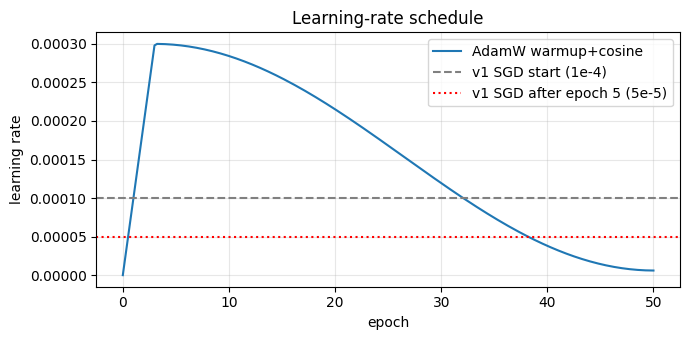

Steps/epoch : 302
Monitor     : val_bin_dice
Compile: PASS


In [19]:
# ============================================================
# 14. LR SCHEDULE + COMPILE
# ============================================================
steps_per_epoch = max(1, len(train_df) // BATCH_SIZE)


@tf.keras.utils.register_keras_serializable(package="MobileUNetLesion")
class WarmupCosine(tf.keras.optimizers.schedules.LearningRateSchedule):
    """Linear warmup then cosine decay. Registered so model.save() works."""

    def __init__(self, base_lr, total_steps, warmup_steps, min_lr_ratio=0.02):
        super().__init__()
        self.base_lr = float(base_lr)
        self.total_steps = int(total_steps)
        self.warmup_steps = int(warmup_steps)
        self.min_lr_ratio = float(min_lr_ratio)

    def __call__(self, step):
        step = tf.cast(step, tf.float32)
        warm = tf.cast(tf.maximum(self.warmup_steps, 1), tf.float32)
        total = tf.cast(tf.maximum(self.total_steps, 1), tf.float32)

        warm_lr = self.base_lr * (step / warm)
        prog = tf.clip_by_value((step - warm) / tf.maximum(total - warm, 1.0), 0.0, 1.0)
        cos_lr = self.base_lr * (
            self.min_lr_ratio
            + (1.0 - self.min_lr_ratio) * 0.5 * (1.0 + tf.cos(math.pi * prog))
        )
        return tf.where(step < warm, warm_lr, cos_lr)

    def get_config(self):
        return {"base_lr": self.base_lr, "total_steps": self.total_steps,
                "warmup_steps": self.warmup_steps, "min_lr_ratio": self.min_lr_ratio}


schedule = WarmupCosine(
    BASE_LR,
    total_steps=TOTAL_EPOCHS * steps_per_epoch,
    warmup_steps=LR_WARMUP_EPOCHS * steps_per_epoch,
)

optimizer = tf.keras.optimizers.AdamW(
    learning_rate=schedule,
    weight_decay=WEIGHT_DECAY,
    global_clipnorm=GLOBAL_CLIPNORM,
)

# Mixed precision (mixed_float16) needs loss scaling to keep fp16 gradients
# from underflowing to zero. Wrap the optimizer whenever that policy is active.
if mixed_precision.global_policy().name == "mixed_float16":
    optimizer = mixed_precision.LossScaleOptimizer(optimizer)
    print("LossScaleOptimizer enabled (mixed_float16 training).")

if USE_DEEP_SUP:
    model.compile(
        optimizer=optimizer,
        loss={k: combined_loss for k in DEEP_SUP_WEIGHTS},
        loss_weights=dict(DEEP_SUP_WEIGHTS),
        metrics={"head_out": METRICS},
        steps_per_execution=1,
    )
    MONITOR = "val_head_out_bin_dice"
    DICE_COL, IOU_COL = "head_out_bin_dice", "head_out_bin_iou"
else:
    model.compile(optimizer=optimizer, loss=combined_loss, metrics=METRICS,
                  steps_per_execution=1)
    MONITOR = "val_bin_dice"
    DICE_COL, IOU_COL = "bin_dice", "bin_iou"

lrs = [float(schedule(s)) for s in range(0, TOTAL_EPOCHS * steps_per_epoch,
                                         max(1, steps_per_epoch // 4))]
plt.figure(figsize=(7, 3.5))
plt.plot(np.linspace(0, TOTAL_EPOCHS, len(lrs)), lrs, label="AdamW warmup+cosine")
plt.axhline(1e-4, ls="--", c="gray", label="v1 SGD start (1e-4)")
plt.axhline(5e-5, ls=":", c="r", label="v1 SGD after epoch 5 (5e-5)")
plt.xlabel("epoch"); plt.ylabel("learning rate"); plt.legend(); plt.grid(alpha=.3)
plt.title("Learning-rate schedule")
plt.tight_layout()
plt.savefig(RUN_DIR / "lr_schedule.png", dpi=140)
plt.show()

print("Steps/epoch :", steps_per_epoch)
print("Monitor     :", MONITOR)
print("Compile: PASS")

In [20]:
# ============================================================
# 15. TRAIN -- 50 EPOCHS (no ReduceLROnPlateau; cosine handles decay)
# ============================================================
BEST_WEIGHTS = RUN_DIR / f"{VARIANT}_best.weights.h5"
FINAL_MODEL  = RUN_DIR / f"{VARIANT}_final.keras"
FINAL_WEIGHTS = RUN_DIR / f"{VARIANT}_final.weights.h5"
HISTORY_CSV  = RUN_DIR / f"{VARIANT}_history.csv"


class EpochTimer(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []

    def on_epoch_begin(self, epoch, logs=None):
        self._t0 = time.time()

    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self._t0)


timer = EpochTimer()
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        str(BEST_WEIGHTS), monitor=MONITOR, mode="max",
        save_best_only=True, save_weights_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(
        monitor=MONITOR, mode="max", patience=EARLY_STOP_PATIENCE,
        restore_best_weights=True, verbose=1),
    tf.keras.callbacks.CSVLogger(str(HISTORY_CSV), append=False),
    tf.keras.callbacks.TerminateOnNaN(),
    timer,
]

print("=" * 70)
print("TRAINING MOBILE-UNET --", VARIANT)
print("=" * 70)
print("Base filters :", BASE_FILTERS, "| depth:", DEPTH, "| size:", IMG_SIZE)
print("Params       :", f"{total_params:,}", f"({fp32_mb:.2f} MB FP32)")
print("Optimizer    : AdamW warmup+cosine, base LR", BASE_LR)
print("Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("Epochs       :", TOTAL_EPOCHS, "| early stop patience:", EARLY_STOP_PATIENCE)
print("=" * 70)

t_start = time.time()

try:
    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=TOTAL_EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )
except tf.errors.ResourceExhaustedError as e:
    print()
    print("=" * 70)
    print("OUT OF GPU MEMORY")
    print("=" * 70)
    print(f"Current config: img_size={IMG_SIZE}, batch_size={BATCH_SIZE}, "
          f"base_filters={BASE_FILTERS}, mixed_precision=True")
    print()
    print("Fix, in order of preference (edit cell 2, restart kernel, rerun):")
    print(f"  1. Halve batch_size:  {BATCH_SIZE} -> {max(1, BATCH_SIZE // 2)}")
    print(f"  2. Drop img_size:     {IMG_SIZE} -> 224  (must stay divisible by {2**DEPTH})")
    print(f"  3. Drop base_filters: {BASE_FILTERS} -> {max(16, BASE_FILTERS // 2)}")
    print("  4. Confirm mixed precision is active (printed at the top of cell 1)")
    print("  5. If Kaggle shows 2 GPUs, confirm no other notebook session holds one")
    print("=" * 70)
    raise

training_seconds = time.time() - t_start

print()
print("=" * 70)
print("TRAINING COMPLETE")
print("=" * 70)
print("Epochs run    :", len(history.history["loss"]))
print("Total minutes :", round(training_seconds / 60.0, 2), " (v1: 236.43)")
print("Mean epoch (s):", round(float(np.mean(timer.times)), 1))

TRAINING MOBILE-UNET -- mu_b_tuned
Base filters : 32 | depth: 4 | size: 256
Params       : 1,552,563 (5.92 MB FP32)
Optimizer    : AdamW warmup+cosine, base LR 0.0003
Loss         : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)
Epochs       : 50 | early stop patience: 14
Epoch 1/50


2026-09-22 09:26:36.543964: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:26:36.696681: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:26:37.755515: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:26:37.931786: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:26:44.320394: E external/local_xla/xla/stream_

199/302 ━━━━━━━━━━━━━━━━━━━━ 47s 459ms/step - bin_dice: 0.2546 - bin_iou: 0.1670 - dice_coef: 0.1823 - iou_coef: 0.1088 - loss: 0.7008

Premature end of JPEG file


302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - bin_dice: 0.2799 - bin_iou: 0.1883 - dice_coef: 0.1969 - iou_coef: 0.1193 - loss: 0.6689

2026-09-22 09:30:25.848131: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:30:25.997993: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:30:27.032856: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-09-22 09:30:27.209194: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


... (95 outputs left out)

Premature end of JPEG file


302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 508ms/step - bin_dice: 0.7066 - bin_iou: 0.5901 - dice_coef: 0.6849 - iou_coef: 0.5617 - loss: 0.2414
Epoch 49: val_bin_dice did not improve from 0.58623
302/302 ━━━━━━━━━━━━━━━━━━━━ 187s 618ms/step - bin_dice: 0.7060 - bin_iou: 0.5880 - dice_coef: 0.6843 - iou_coef: 0.5597 - loss: 0.2419 - val_bin_dice: 0.5799 - val_bin_iou: 0.4677 - val_dice_coef: 0.5664 - val_iou_coef: 0.4491 - val_loss: 0.3543
Epoch 50/50
 47/302 ━━━━━━━━━━━━━━━━━━━━ 2:03 483ms/step - bin_dice: 0.7045 - bin_iou: 0.5860 - dice_coef: 0.6788 - iou_coef: 0.5535 - loss: 0.2420

Premature end of JPEG file


302/302 ━━━━━━━━━━━━━━━━━━━━ 0s 497ms/step - bin_dice: 0.7114 - bin_iou: 0.5948 - dice_coef: 0.6883 - iou_coef: 0.5648 - loss: 0.2394
Epoch 50: val_bin_dice did not improve from 0.58623
302/302 ━━━━━━━━━━━━━━━━━━━━ 184s 609ms/step - bin_dice: 0.7093 - bin_iou: 0.5924 - dice_coef: 0.6866 - iou_coef: 0.5630 - loss: 0.2397 - val_bin_dice: 0.5813 - val_bin_iou: 0.4681 - val_dice_coef: 0.5680 - val_iou_coef: 0.4500 - val_loss: 0.3521
Restoring model weights from the end of the best epoch: 44.

TRAINING COMPLETE
Epochs run    : 50
Total minutes : 149.92  (v1: 236.43)
Mean epoch (s): 179.9


Best epoch    : 44 of 50
Best val Dice : 0.5862   (v1 = 0.3005)
Best val IoU  : 0.4741   (v1 = 0.1982)
Improvement   : +95.1% vs v1
Train-val gap : +0.1158  -> healthy fit


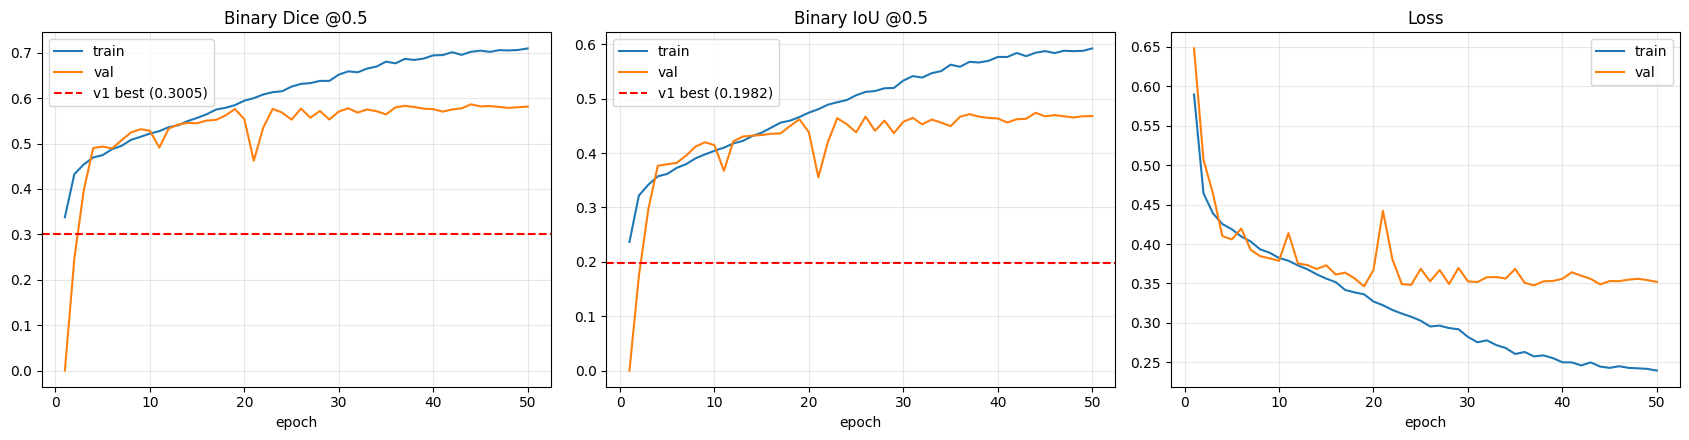

In [21]:
# ============================================================
# 16. CURVES + FIT DIAGNOSIS
# ============================================================
history_df = pd.read_csv(HISTORY_CSV)
history_df["global_epoch"] = np.arange(1, len(history_df) + 1)

assert f"val_{DICE_COL}" in history_df.columns, (
    f"Missing column val_{DICE_COL}. Found: {list(history_df.columns)}"
)

best_idx = int(history_df[f"val_{DICE_COL}"].idxmax())
best_epoch = int(history_df.loc[best_idx, "global_epoch"])
best_dice = float(history_df.loc[best_idx, f"val_{DICE_COL}"])
best_iou = float(history_df.loc[best_idx, f"val_{IOU_COL}"])
gap = float(history_df.loc[best_idx, DICE_COL]) - best_dice

if gap < 0.03:
    verdict = "STILL UNDERFITTING -> raise base_filters / LR"
elif gap > 0.15:
    verdict = "OVERFITTING -> raise dropout / weight decay"
else:
    verdict = "healthy fit"

print("Best epoch    :", best_epoch, "of", len(history_df))
print("Best val Dice :", f"{best_dice:.4f}   (v1 = {V1_DICE:.4f})")
print("Best val IoU  :", f"{best_iou:.4f}   (v1 = {V1_IOU:.4f})")
print("Improvement   :", f"{(best_dice / V1_DICE - 1) * 100:+.1f}% vs v1")
print("Train-val gap :", f"{gap:+.4f}  ->", verdict)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

axes[0].plot(history_df["global_epoch"], history_df[DICE_COL], label="train")
axes[0].plot(history_df["global_epoch"], history_df[f"val_{DICE_COL}"], label="val")
axes[0].axhline(V1_DICE, ls="--", c="r", label=f"v1 best ({V1_DICE:.4f})")
axes[0].set_title("Binary Dice @0.5")

axes[1].plot(history_df["global_epoch"], history_df[IOU_COL], label="train")
axes[1].plot(history_df["global_epoch"], history_df[f"val_{IOU_COL}"], label="val")
axes[1].axhline(V1_IOU, ls="--", c="r", label=f"v1 best ({V1_IOU:.4f})")
axes[1].set_title("Binary IoU @0.5")

axes[2].plot(history_df["global_epoch"], history_df["loss"], label="train")
axes[2].plot(history_df["global_epoch"], history_df["val_loss"], label="val")
axes[2].set_title("Loss")

for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(); ax.grid(alpha=.3)

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_curves.png", dpi=150)
plt.show()

Best checkpoint reloaded.


Predicting val:   0%|          | 0/76 [00:00<?, ?it/s]

Validation tensor: (455, 256, 256)
 threshold   dice    iou  precision  recall
    0.1000 0.5785 0.4638     0.5412  0.8132
    0.1500 0.5820 0.4681     0.5550  0.7956
    0.2000 0.5839 0.4705     0.5648  0.7825
    0.2500 0.5848 0.4718     0.5725  0.7715
    0.3000 0.5857 0.4729     0.5794  0.7623
    0.3500 0.5862 0.4738     0.5856  0.7538
    0.4000 0.5864 0.4741     0.5912  0.7453
    0.4500 0.5864 0.4741     0.5966  0.7372
    0.5000 0.5860 0.4739     0.6017  0.7292
    0.5500 0.5855 0.4735     0.6067  0.7210
    0.6000 0.5847 0.4728     0.6118  0.7124
    0.6500 0.5835 0.4717     0.6170  0.7029
    0.7000 0.5818 0.4700     0.6226  0.6922
    0.7500 0.5793 0.4675     0.6286  0.6796
    0.8000 0.5758 0.4639     0.6355  0.6643
    0.8500 0.5708 0.4586     0.6467  0.6448
    0.9000 0.5617 0.4485     0.6628  0.6140

Best threshold : 0.4  Dice: 0.5864


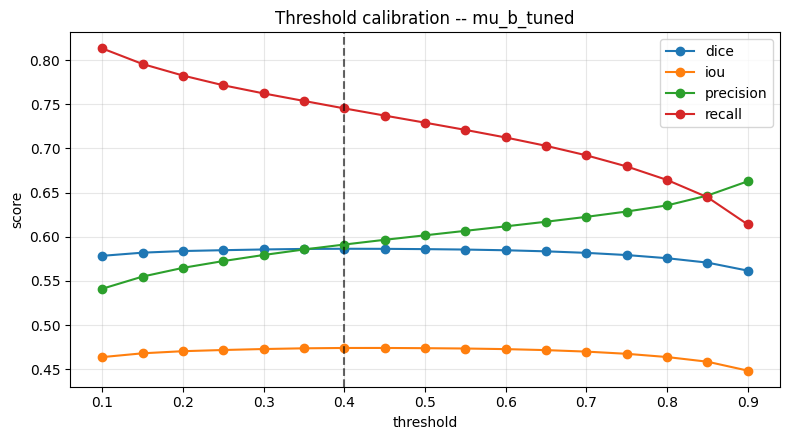

In [22]:
# ============================================================
# 17. THRESHOLD CALIBRATION
# ============================================================
model.load_weights(str(BEST_WEIGHTS))
print("Best checkpoint reloaded.")

probs_list, gts_list = [], []
for xb, yb in tqdm(val_ds, desc="Predicting val"):
    out = model.predict(xb, verbose=0)
    pm = out[0] if isinstance(out, (list, tuple)) else out
    probs_list.append(pm[..., 0].astype(np.float32))
    gts_list.append(main_target(yb).numpy()[..., 0].astype(np.float32))

probs = np.concatenate(probs_list, axis=0)
gts = np.concatenate(gts_list, axis=0)
del probs_list, gts_list

assert probs.shape == gts.shape, f"shape mismatch {probs.shape} vs {gts.shape}"
assert len(probs) == len(val_df), (
    f"prediction count {len(probs)} != val rows {len(val_df)}"
)
print("Validation tensor:", probs.shape)


def sweep(probs, gts, thresholds):
    rows = []
    gt_flat = gts.reshape(gts.shape[0], -1)
    gt_sum = gt_flat.sum(1)
    pr_all = probs.reshape(probs.shape[0], -1)
    for t in thresholds:
        pr = (pr_all >= t).astype(np.float32)
        inter = (gt_flat * pr).sum(1)
        pr_sum = pr.sum(1)
        rows.append({
            "threshold": float(t),
            "dice": float(((2 * inter + 1e-6) / (gt_sum + pr_sum + 1e-6)).mean()),
            "iou": float(((inter + 1e-6) / (gt_sum + pr_sum - inter + 1e-6)).mean()),
            "precision": float(((inter + 1e-6) / (pr_sum + 1e-6)).mean()),
            "recall": float(((inter + 1e-6) / (gt_sum + 1e-6)).mean()),
        })
    return pd.DataFrame(rows)


sweep_df = sweep(probs, gts, THRESHOLD_GRID)
sweep_df.to_csv(RUN_DIR / f"{VARIANT}_threshold_sweep.csv", index=False)

best_row = sweep_df.loc[sweep_df["dice"].idxmax()]
BEST_THRESHOLD = float(best_row["threshold"])

print(sweep_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print()
print("Best threshold :", BEST_THRESHOLD, " Dice:", f"{best_row['dice']:.4f}")

plt.figure(figsize=(8, 4.5))
for col in ["dice", "iou", "precision", "recall"]:
    plt.plot(sweep_df["threshold"], sweep_df[col], marker="o", label=col)
plt.axvline(BEST_THRESHOLD, ls="--", c="k", alpha=.6)
plt.xlabel("threshold"); plt.ylabel("score"); plt.legend(); plt.grid(alpha=.3)
plt.title(f"Threshold calibration -- {VARIANT}")
plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_threshold_curve.png", dpi=150)
plt.show()

In [23]:
# ============================================================
# 18. FINAL EVAL + LESION-SIZE BREAKDOWN
# ============================================================
pred_bin = (probs >= BEST_THRESHOLD).astype(np.float32)
gt_flat = gts.reshape(gts.shape[0], -1)
pr_flat = pred_bin.reshape(pred_bin.shape[0], -1)

inter = (gt_flat * pr_flat).sum(1)
dice_per_image = (2 * inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) + 1e-6)
iou_per_image = (inter + 1e-6) / (gt_flat.sum(1) + pr_flat.sum(1) - inter + 1e-6)

final_dice = float(dice_per_image.mean())
final_iou = float(iou_per_image.mean())

print("=" * 60)
print("FINAL VALIDATION --", VARIANT)
print("=" * 60)
print(f"Threshold        : {BEST_THRESHOLD}")
print(f"Dice             : {final_dice:.4f}   (v1: {V1_DICE:.4f})")
print(f"IoU              : {final_iou:.4f}   (v1: {V1_IOU:.4f})")
print(f"Dice std         : {float(dice_per_image.std()):.4f}")
print(f"Images Dice>0.5  : {int((dice_per_image > 0.5).sum())} / {len(dice_per_image)}")
print(f"Images Dice<0.1  : {int((dice_per_image < 0.1).sum())} / {len(dice_per_image)}")

size_df = val_df.copy()
size_df["dice"] = dice_per_image
size_df["iou"] = iou_per_image
size_df["size_bin"] = pd.cut(size_df["lesion_frac"],
                             bins=[0, .01, .05, .15, 1.0],
                             labels=["<1%", "1-5%", "5-15%", ">15%"])

breakdown = size_df.groupby("size_bin", observed=True).agg(
    images=("dice", "size"), mean_dice=("dice", "mean"), mean_iou=("iou", "mean")
).round(4)

print()
print("Performance by lesion size:")
print(breakdown.to_string())
breakdown.to_csv(RUN_DIR / f"{VARIANT}_size_breakdown.csv")

FINAL VALIDATION -- mu_b_tuned
Threshold        : 0.4
Dice             : 0.5864   (v1: 0.3005)
IoU              : 0.4741   (v1: 0.1982)
Dice std         : 0.2934
Images Dice>0.5  : 287 / 455
Images Dice<0.1  : 40 / 455

Performance by lesion size:
          images  mean_dice  mean_iou
size_bin                             
<1%           59     0.2476    0.1662
1-5%         136     0.4661    0.3376
5-15%        122     0.6640    0.5378
>15%         138     0.7813    0.6840


In [24]:
# ============================================================
# 19. SAVE ARTIFACTS + MODEL-SIZE COMPARISON
# ============================================================
model.save(str(FINAL_MODEL))
model.save_weights(str(FINAL_WEIGHTS))

with open(RUN_DIR / f"{VARIANT}_architecture.json", "w") as f:
    f.write(model.to_json())

on_disk_mb = FINAL_MODEL.stat().st_size / (1024 ** 2)
weights_mb = FINAL_WEIGHTS.stat().st_size / (1024 ** 2)

with open(RUN_DIR / f"{VARIANT}_inference_config.json", "w") as f:
    json.dump({
        "variant": VARIANT, "family": "Mobile-UNet",
        "img_size": IMG_SIZE, "letterbox": LETTERBOX_RESIZE,
        "input_range": "[0,255] float32 (model rescales internally)",
        "best_threshold": BEST_THRESHOLD,
        "val_dice": final_dice, "val_iou": final_iou,
        "total_params": total_params, "fp32_mb": round(fp32_mb, 2),
        "keras_file_mb": round(on_disk_mb, 2),
    }, f, indent=2)

summary = {
    "variant": VARIANT,
    "family": "Mobile-UNet",
    "base_filters": BASE_FILTERS,
    "img_size": IMG_SIZE,
    "batch_size": BATCH_SIZE,
    "residual": USE_RESIDUAL,
    "gates": USE_GATES,
    "cbam": USE_CBAM,
    "aspp": USE_ASPP,
    "deep_sup": USE_DEEP_SUP,
    "optimizer": f"AdamW cosine lr={BASE_LR}",
    "loss": "0.5*BCE + 0.5*FocalTversky(0.3,0.7)",
    "total_params": total_params,
    "trainable_params": trainable_params,
    "fp32_mb": round(fp32_mb, 2),
    "keras_file_mb": round(on_disk_mb, 2),
    "weights_file_mb": round(weights_mb, 2),
    "epochs_run": len(history_df),
    "best_epoch": best_epoch,
    "best_threshold": BEST_THRESHOLD,
    "val_dice": round(final_dice, 4),
    "val_iou": round(final_iou, 4),
    "train_val_gap": round(gap, 4),
    "training_minutes": round(training_seconds / 60.0, 2),
}

pd.DataFrame([summary]).to_csv(RUN_DIR / f"{VARIANT}_summary.csv", index=False)

V1_ROW = {
    "variant": "v1_original", "family": "Mobile-UNet", "base_filters": 16,
    "img_size": 256, "batch_size": 16, "residual": False, "gates": False,
    "cbam": True, "aspp": False, "deep_sup": False,
    "optimizer": "SGD+Nesterov 1e-4 -> 5e-5", "loss": "BCE + Dice",
    "total_params": V1_PARAMS, "trainable_params": 308375,
    "fp32_mb": round(V1_PARAMS * 4 / 1024 ** 2, 2),
    "keras_file_mb": np.nan, "weights_file_mb": np.nan,
    "epochs_run": 55, "best_epoch": 55, "best_threshold": 0.5,
    "val_dice": round(V1_DICE, 4), "val_iou": round(V1_IOU, 4),
    "train_val_gap": 0.0093, "training_minutes": 236.43,
}

if COMPARE_CSV.exists():
    comp = pd.read_csv(COMPARE_CSV)
    comp = comp[comp["variant"] != VARIANT]
    comp = pd.concat([comp, pd.DataFrame([summary])], ignore_index=True)
    if "v1_original" not in set(comp["variant"]):
        comp = pd.concat([pd.DataFrame([V1_ROW]), comp], ignore_index=True)
else:
    comp = pd.DataFrame([V1_ROW, summary])

comp = comp.sort_values("total_params").reset_index(drop=True)
comp.to_csv(COMPARE_CSV, index=False)

print("Saved:", FINAL_MODEL, f"({on_disk_mb:.2f} MB on disk)")
print()
print("=" * 104)
print("MOBILE-UNET SIZE vs ACCURACY COMPARISON")
print("=" * 104)
print(comp[["variant", "base_filters", "img_size", "total_params", "fp32_mb",
            "keras_file_mb", "best_epoch", "best_threshold",
            "val_dice", "val_iou", "training_minutes"]]
      .to_string(index=False))
print()
print("Efficiency (Dice per 100k params):")
for _, r in comp.iterrows():
    eff = r["val_dice"] / (r["total_params"] / 1e5)
    print(f"  {r['variant']:<18}{eff:>8.4f}")

Saved: /kaggle/working/Segmentation Output/lesion_mu_b_tuned/mu_b_tuned_final.keras (18.22 MB on disk)

MOBILE-UNET SIZE vs ACCURACY COMPARISON
    variant  base_filters  img_size  total_params  fp32_mb  keras_file_mb  best_epoch  best_threshold  val_dice  val_iou  training_minutes
v1_original            16       256        311319     1.19            NaN          55             0.5    0.3005   0.1982            236.43
 mu_b_tuned            32       256       1552563     5.92          18.22          44             0.4    0.5864   0.4741            149.92

Efficiency (Dice per 100k params):
  v1_original         0.0965
  mu_b_tuned          0.0378


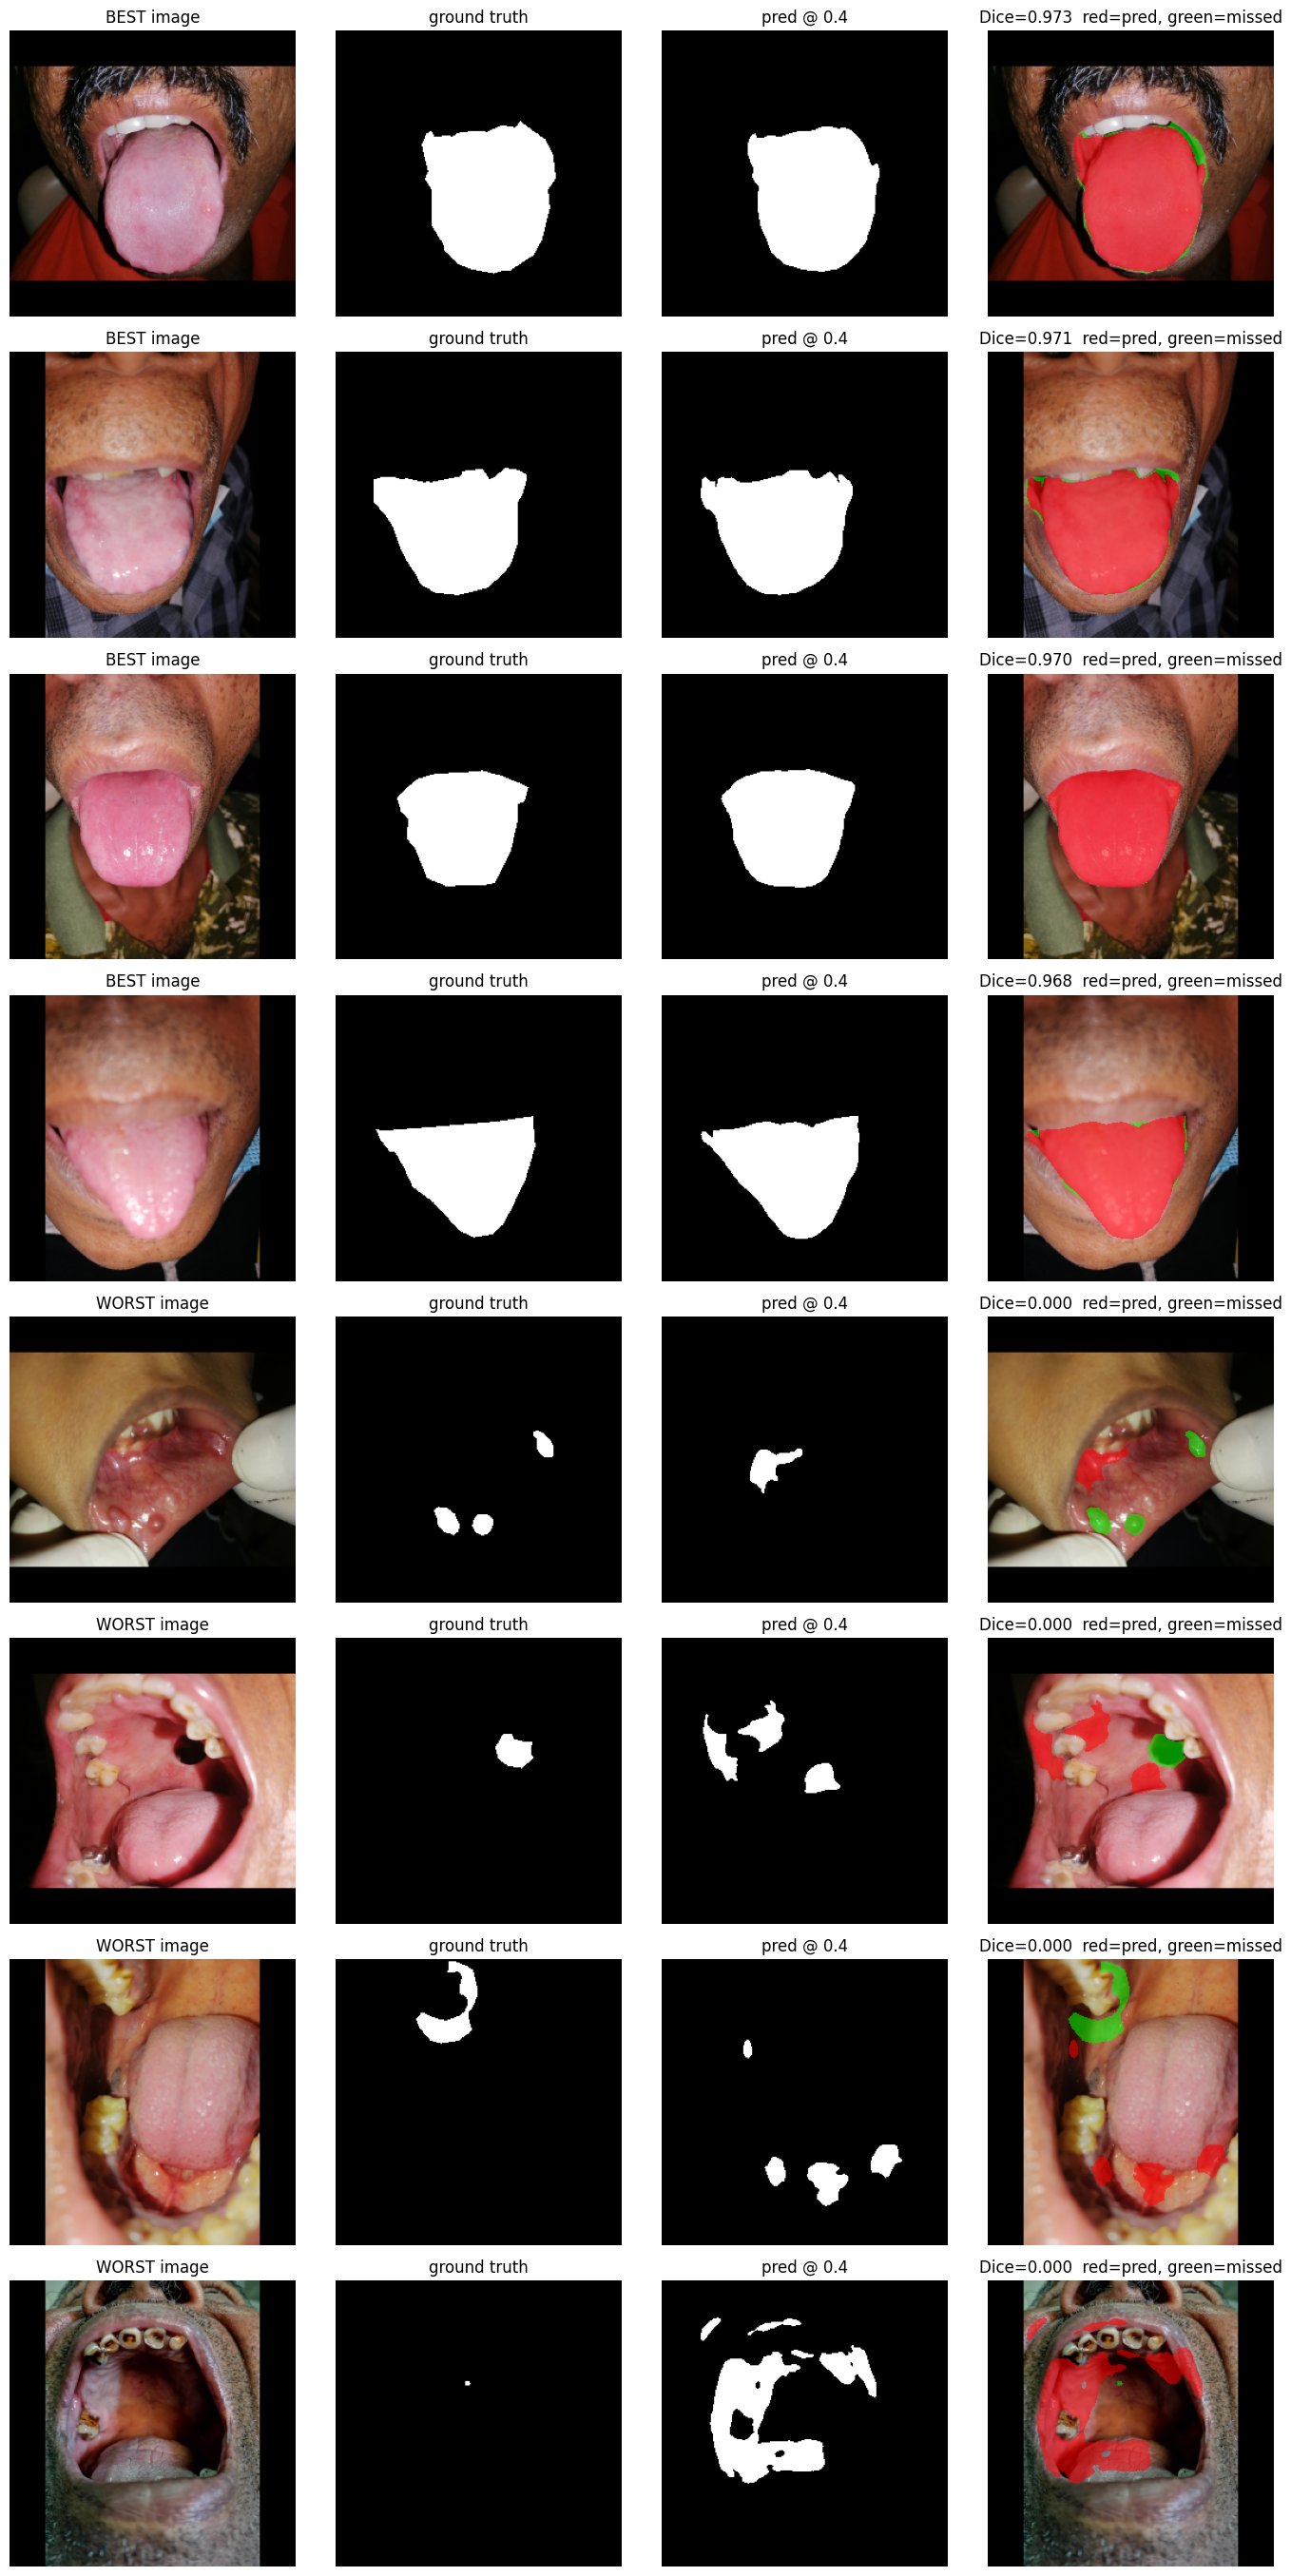

In [25]:
# ============================================================
# 20. QUALITATIVE PREDICTIONS (4 best + 4 worst)
# ============================================================
SEG_DIR = RUN_DIR / "final_segmented"
SEG_DIR.mkdir(parents=True, exist_ok=True)

order = np.argsort(-dice_per_image)
show_idx = list(order[:4]) + list(order[-4:])

fig, axes = plt.subplots(len(show_idx), 4, figsize=(14, 3.4 * len(show_idx)))

for r, idx in enumerate(show_idx):
    idx = int(idx)
    row = val_df.iloc[idx]

    img = safe_imread(row["image_path"], cv2.IMREAD_COLOR)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = (letterbox(img, IMG_SIZE, cv2.INTER_AREA) if LETTERBOX_RESIZE
           else cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA))

    gt = (gts[idx] * 255).astype(np.uint8)
    pm = (pred_bin[idx] * 255).astype(np.uint8)

    ov = img.copy()
    hit = pm > 0
    miss = (gt > 0) & (pm == 0)
    ov[hit] = (0.45 * ov[hit] + 0.55 * np.array([255, 0, 0])).astype(np.uint8)
    ov[miss] = (0.45 * ov[miss] + 0.55 * np.array([0, 255, 0])).astype(np.uint8)

    tag = "BEST" if r < 4 else "WORST"
    axes[r, 0].imshow(img);             axes[r, 0].set_title(f"{tag} image")
    axes[r, 1].imshow(gt, cmap="gray"); axes[r, 1].set_title("ground truth")
    axes[r, 2].imshow(pm, cmap="gray"); axes[r, 2].set_title(f"pred @ {BEST_THRESHOLD}")
    axes[r, 3].imshow(ov)
    axes[r, 3].set_title(f"Dice={dice_per_image[idx]:.3f}  red=pred, green=missed")
    for c in range(4):
        axes[r, c].axis("off")

    cv2.imwrite(str(SEG_DIR / f"{row['image_id']}_pred.png"),
                cv2.cvtColor(ov, cv2.COLOR_RGB2BGR))

plt.tight_layout()
plt.savefig(RUN_DIR / f"{VARIANT}_predictions.png", dpi=140)
plt.show()

In [26]:
# ============================================================
# 21. FINAL AUDIT
# ============================================================
required = [
    BEST_WEIGHTS, FINAL_MODEL, FINAL_WEIGHTS, HISTORY_CSV,
    RUN_DIR / f"{VARIANT}_summary.csv",
    RUN_DIR / f"{VARIANT}_architecture.json",
    RUN_DIR / f"{VARIANT}_inference_config.json",
    RUN_DIR / f"{VARIANT}_threshold_sweep.csv",
    RUN_DIR / f"{VARIANT}_size_breakdown.csv",
    RUN_DIR / f"{VARIANT}_curves.png",
    RUN_DIR / f"{VARIANT}_predictions.png",
]
missing = [str(p) for p in required if not p.exists()]
print("Missing artifacts:", missing if missing else "none")
assert not missing, "STOP: artifacts missing."

print()
print("Audit")
print("  Architecture family    : Mobile-UNet (depthwise separable) ONLY")
print("  External backbone      : NONE")
print("  Pretrained weights     : NONE")
print("  Transfer learning      : NONE")
print("  Variant                :", VARIANT)
print("  Base filters           :", BASE_FILTERS, "(v1: 16)")
print("  Residual sep blocks    :", USE_RESIDUAL)
print("  Attention gates        :", USE_GATES)
print("  CBAM bottleneck        :", USE_CBAM)
print("  ASPP bottleneck        :", USE_ASPP)
print("  Deep supervision       :", USE_DEEP_SUP)
print("  Zero-init adapters     : REMOVED")
print("  Layer-name registry    : ACTIVE (duplicate names impossible)")
print("  All variants build-test: PASSED before training")
print("  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)")
print("  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)")
print("  Custom objects         : registered (save/load safe)")
print("  Resize                 :", "letterbox" if LETTERBOX_RESIZE else "square squash")
print("  Vertical flip / rot90  : NO")
print("  Split                  : stratified by lesion area, leak-checked")
print("  Threshold              : calibrated ->", BEST_THRESHOLD)
print("  Epoch budget           :", TOTAL_EPOCHS)
print()
print(f"  SIZE    {total_params:,} params | {fp32_mb:.2f} MB FP32 | {on_disk_mb:.2f} MB .keras")
print(f"  RESULT  Dice {final_dice:.4f} | IoU {final_iou:.4f}")
print(f"  v1      Dice {V1_DICE:.4f} | IoU {V1_IOU:.4f} | {V1_PARAMS:,} params")
print()
print("Mobile-UNet lesion audit: PASS")

Missing artifacts: none

Audit
  Architecture family    : Mobile-UNet (depthwise separable) ONLY
  External backbone      : NONE
  Pretrained weights     : NONE
  Transfer learning      : NONE
  Variant                : mu_b_tuned
  Base filters           : 32 (v1: 16)
  Residual sep blocks    : True
  Attention gates        : True
  CBAM bottleneck        : True
  ASPP bottleneck        : False
  Deep supervision       : False
  Zero-init adapters     : REMOVED
  Layer-name registry    : ACTIVE (duplicate names impossible)
  All variants build-test: PASSED before training
  Optimizer              : AdamW warmup+cosine (no ReduceLROnPlateau)
  Loss                   : 0.5*BCE + 0.5*FocalTversky(0.3, 0.7)
  Custom objects         : registered (save/load safe)
  Resize                 : letterbox
  Vertical flip / rot90  : NO
  Split                  : stratified by lesion area, leak-checked
  Threshold              : calibrated -> 0.4
  Epoch budget           : 50

  SIZE    1,552,563 p

## Running the other variants

1. Change `VARIANT` in cell 2.
2. Restart the kernel.
3. Run all cells — masks are cached, so only training re-runs.
4. Every run appends to `mobileunet_variant_comparison.csv` with params, FP32 MB,
   on-disk MB, Dice, IoU and Dice-per-100k-params efficiency.

Order: `mu_a_ablation` → `mu_b_tuned` → `mu_c_wide_aspp` → `mu_d_deepsup`.

Cell 16 prints a fit verdict. If it says **STILL UNDERFITTING**, raise `base_filters`
to 64 then `lr` to `5e-4` in the `VARIANTS` dict. If it says **OVERFITTING**, raise
`dropout` and `WEIGHT_DECAY`.
